In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt





FILE_PATH = "../data/k_20ms_avg128_26.5degC.csv"


In [18]:
raw = pd.read_csv(FILE_PATH, header=None)

In [ ]:
df = raw.copy()

df_x = df.iloc[:, 3].values
df_y = df.iloc[:, 4].values

df_x = np.array(df_x)
df_y = np.array(df_y)

df_x = df_x * 1e6 # Convert to microseconds
df_y = df_y * 1e3 # Convert to millivolts

/var/folders/s0/bjy5pjdn6fnc705xyf1qflfw0000gn/T/ipykernel_74371/4051941421.py:40: RuntimeWarning: divide by zero encountered in divide
  self.estimated_mz = ref_mz * (ref_hz / fundamental_hz) ** 2


ValueError: Expected one m/z value per positive FFT bin

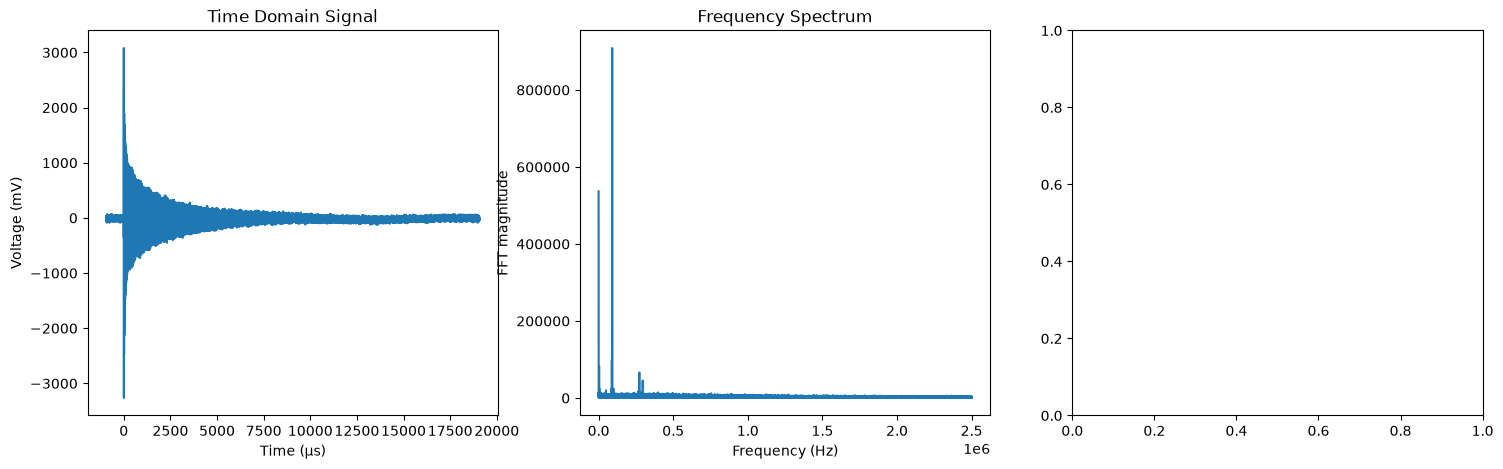

In [ ]:
import numpy as np
import pandas as pd
from scipy.signal.windows import blackmanharris


class DataProcessor:
    def __init__(self, x, y):
        self.x = np.asarray(x, dtype=float)
        self.y = np.asarray(y, dtype=float)
        
        self.dft_freq = None
        self.dft_mag = None
        self.estimated_mz = None

    @classmethod
    def load_data(cls, file_path):
        data = pd.read_csv(file_path, header=None)

        x = pd.to_numeric(data.iloc[:, 3], errors="raise").to_numpy() * 1e6
        y = pd.to_numeric(data.iloc[:, 4], errors="raise").to_numpy() * 1e3

        return cls(x, y)

    def dft(self):
        if self.dft_freq is None or self.dft_mag is None:
            sample_spacing_seconds = (self.x[1] - self.x[0]) * 1e-6
            n_samples = self.y.size

            window = blackmanharris(n_samples, sym=False)
            spectrum = np.fft.rfft(self.y * window)

            self.dft_freq = np.fft.rfftfreq(n_samples, d=sample_spacing_seconds)
            self.dft_mag = np.abs(spectrum)

        return self.dft_freq, self.dft_mag

    def frequency_to_mz(self, *, ref_hz=116, ref_mz=23, harmonic_order=1):
        frequencies, _ = self.dft()
        fundamental_hz = frequencies[frequencies > 0] / harmonic_order
        self.estimated_mz = ref_mz * (ref_hz / fundamental_hz) ** 2
        return self.estimated_mz



    def plot(self):
        n_panels = 1
        if self.dft_freq is not None and self.dft_mag is not None:
            n_panels += 1
        if self.estimated_mz is not None:
            n_panels +=1

        ffig, axes = plt.subplots(
            1, n_panels, figsize=(6 * n_panels, 5), squeeze=False
        )
        axes = axes[0]

        axes[0].plot(self.x, self.y)
        axes[0].set(
        title="Time Domain Signal",
        xlabel="Time (µs)",
        ylabel="Voltage (mV)")

        if self.dft_freq is not None and self.dft_mag is not None:
            n_panels += 1
            axes[1].plot(self.dft_freq, self.dft_mag)
            axes[1].set(
                title="Frequency Spectrum",
                xlabel="Frequency (Hz)",
                ylabel="FFT magnitude",
            )

        if self.estimated_mz is not None:
            n_panels += 1
            positive = self.dft_freq > 0
            mz = np.asarray(self.estimated_mz)
            magnitude = self.dft_mag[positive]

            if mz.shape != magnitude.shape:
                raise ValueError("Expected one m/z value per positive FFT bin")

            order = np.argsort(mz)
            axes[2].plot(mz[order], magnitude[order])
            axes[2].set(
                title="Mass-to-Charge Spectrum",
                xlabel="m/z",
                ylabel="FFT magnitude",
            )



        plt.tight_layout()
        plt.show()

if __name__ == "__main__":
    FILE_PATH = "../data/k_20ms_avg128_26.5degC.csv"

    processor = DataProcessor.load_data(FILE_PATH)
    processor.dft()
    processor.frequency_to_mz()



    processor.plot()